<a href="https://colab.research.google.com/github/MertSenturk578/end-to-end-laptop-prediction/blob/main/Yapay_Zeka_i%C3%A7in_Pyhton_Proje_Mert%C5%9Eent%C3%BCrk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚀 **Uçtan Uca Dizüstü Bilgisayar Fiyat Tahmini ve Akıllı Öneri Sistemi**

## **Proje Tanım Formu:**
## **Problem Cümlesi:** Piyasada şirketlerin toplu donanım alımları ve tedarik dalgalanmaları nedeniyle gereksiz oranda yükselen dizüstü bilgisayar fiyatlarını; cihazın markası, işlemcisi, RAM'i, ekran boyutu ve ağırlığı gibi özelliklerine bakarak ne kadar doğru tahmin edebiliriz?
## **Hedef Değişken (y):**`Price_tl` (Dizüstü bilgisayarın Türk Lirası cinsinden piyasa fiyatı)
##  **Problem Türü:** Regresyon (Sayısal bir değer / fiyat tahmini yapılacağı için)

### **💡 Veri Seti ve Fiyatlandırma Yaklaşımı:**
Projede kullanılan dizüstü bilgisayar veri seti küresel pazardaki tarihsel bir referans (baseline) veri setini temsil etmektedir. Modelin günümüz Türkiye pazarındaki nominal fiyat gerçekliğiyle örtüşebilmesi ve son kullanıcıya anlamlı bir bütçe projeksiyonu sunabilmesi amacıyla fiyatlar, güncel serbest piyasa döviz kuru (~55.57 TL) baz alınarak Türk Lirası'na endekslenmiş ve analizler bu nominal bütçe üzerinden kurgulanmıştır.
## **Gerekçe ve Çözüm Yaklaşımı (Neden Bu Proje?):**
## Günümüz bilgisayar pazarında şirketlerinin yüklü miktardaki donanım alımları piyasa fiyatlarını yukarı çekmektedir. Bu çalışmanın temel amacı; laptop fiyatlarının en çok hangi donanım bileşenlerinden etkilendiğini veri bilimiyle ortaya koymak; bu sayede tüketicilerin piyasa koşullarına göre en uygun **fiyat-performans** bilgisayarlarını bulup alabilmesi için akıllı bir seçim ve tahmin sistemi sunmaktır.

## **Kullanılan Araçlar:**
## Python, Pandas, NumPy, Scikit-Learn, Matplotlib, Seaborn, Gradio (Arayüz)


### 📚Kütüphanlerin Yüklenmesi

In [1]:
# Projede Kullanılan Tüm Kütüphaneler ve Araçlar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Makine Öğrenmesi Modelleri ve Araçları (Scikit-Learn)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Arayüz / UI (Gradio veya Ipywidgets)
import gradio as gr

print("Tüm kütüphaneler başarıyla yüklendi ve içe aktarıldı")

Tüm kütüphaneler başarıyla yüklendi ve içe aktarıldı


### 🔍Veri setinin yüklenmesi ve veri seti Hakkında bilgi edinmek

In [2]:
# Veri seti local dışındada çalışabilmesi için veri setii githuba yükleyip url den kullanıcaz
url = "https://raw.githubusercontent.com/MertSenturk578/end-to-end-laptop-prediction/refs/heads/main/laptop_price.csv"

# veriyi urlden okutuyoruz
df = pd.read_csv(url)

print("Veri Seti Boyutu (Satır, Sütun):", df.shape)
print("-" * 50)
df.info()
print("-" * 50)
df.head(10)

Veri Seti Boyutu (Satır, Sütun): (1303, 13)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   Product           1303 non-null   object 
 3   TypeName          1303 non-null   object 
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   object 
 6   Cpu               1303 non-null   object 
 7   Ram               1303 non-null   object 
 8   Memory            1303 non-null   object 
 9   Gpu               1303 non-null   object 
 10  OpSys             1303 non-null   object 
 11  Weight            1303 non-null   object 
 12  Price_euros       1303 non-null   float64
dtypes: float64(2), int64(1), object(10)
memory usage: 132.5+ KB
----------------------------

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60
5,6,Acer,Aspire 3,Notebook,15.6,1366x768,AMD A9-Series 9420 3GHz,4GB,500GB HDD,AMD Radeon R5,Windows 10,2.1kg,400.00
6,7,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.2GHz,16GB,256GB Flash Storage,Intel Iris Pro Graphics,Mac OS X,2.04kg,2139.97
7,8,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,256GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,1158.70
8,9,Asus,ZenBook UX430UN,Ultrabook,14.0,Full HD 1920x1080,Intel Core i7 8550U 1.8GHz,16GB,512GB SSD,Nvidia GeForce MX150,Windows 10,1.3kg,1495.00
9,10,Acer,Swift 3,Ultrabook,14.0,IPS Panel Full HD 1920x1080,Intel Core i5 8250U 1.6GHz,8GB,256GB SSD,Intel UHD Graphics 620,Windows 10,1.6kg,770.00


### 🧹Veri Seti Temizleme (Data Cleaning) Aşaması ve euro tl kur çevirisi ve veri setinin temizlik sonrası görüntüsü

In [3]:
# RAM ve Ağırlık (Weight) sütunlarındaki metin birimlerini temizleyip sayıya çeviriyoruz
df['Ram'] = df['Ram'].str.replace('GB', '').astype(int)
df['Weight'] = df['Weight'].str.replace('kg', '').astype(float)

# Eksik (Null) Değer Kontrolü: Veri setimizde eksik veri olup olmadığını kontrol ediyoruz.
print("Eksik Değer Sayıları:")
print(df.isnull().sum())
print("-" * 50)

# Güncel kur ile Euro fiyatlarını TL'ye çeviriyoruz (Kasım 2026 kuru: ~55.57 TL veri setimiz eski olmasına rağmen güncel fiyatlarımıza uyum sağlaması adına güncel kur kullanıldı.)
euro_kuru = 55.57

# Fiyatları TL'ye çevirip virgülden sonra 2 basamağa (.round(2)) yuvarlıyoruz
df['Price_tl'] = (df['Price_euros'] * euro_kuru).round(2)

# Orijinal Euro sütununu veri setinden kaldırıyoruz (artık Price_tl ile devam edeceğiz)
df.drop(columns=['Price_euros'], inplace=True)

print("Fiyatlar başarıyla TL'ye çevrildi ve yuvarlandı!")
display(df[['Company', 'Ram', 'Weight', 'Price_tl']].head())
# Temizlik ve kontroller sonrası veri setinin son durumunu ve tiplerini inceliyoruz.
df.info()
print("-" * 50)
display(df.describe())
print("-" * 50)
df.head(10) #ram ve weight satırlarının değişmiş hallerini görelim

Eksik Değer Sayıları:
laptop_ID           0
Company             0
Product             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price_euros         0
dtype: int64
--------------------------------------------------
Fiyatlar başarıyla TL'ye çevrildi ve yuvarlandı!


,Company,Ram,Weight,Price_tl
0,Apple,8,1.37,74446.57
1,Apple,8,1.34,49954.10
2,HP,8,1.86,31952.75
3,Apple,16,1.83,141006.10
4,Apple,8,1.37,100226.05


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   Product           1303 non-null   object 
 3   TypeName          1303 non-null   object 
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   object 
 6   Cpu               1303 non-null   object 
 7   Ram               1303 non-null   int64  
 8   Memory            1303 non-null   object 
 9   Gpu               1303 non-null   object 
 10  OpSys             1303 non-null   object 
 11  Weight            1303 non-null   float64
 12  Price_tl          1303 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 132.5+ KB
--------------------------------------------------


,laptop_ID,Inches,Ram,Weight,Price_tl
count,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000
mean,660.155794,15.017191,8.382195,2.038734,62443.285948
std,381.172104,1.426304,5.084665,0.665475,38843.932552
min,1.000000,10.100000,2.000000,0.690000,9669.180000
25%,331.500000,14.000000,4.000000,1.500000,33286.430000
50%,659.000000,15.600000,8.000000,2.040000,54291.890000
75%,990.500000,15.600000,8.000000,2.300000,82681.490000
max,1320.000000,18.400000,64.000000,4.700000,338921.430000


--------------------------------------------------


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_tl
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,74446.57
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,49954.10
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,31952.75
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,141006.10
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,100226.05
5,6,Acer,Aspire 3,Notebook,15.6,1366x768,AMD A9-Series 9420 3GHz,4,500GB HDD,AMD Radeon R5,Windows 10,2.10,22228.00
6,7,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.2GHz,16,256GB Flash Storage,Intel Iris Pro Graphics,Mac OS X,2.04,118918.13
7,8,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,256GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,64388.96
8,9,Asus,ZenBook UX430UN,Ultrabook,14.0,Full HD 1920x1080,Intel Core i7 8550U 1.8GHz,16,512GB SSD,Nvidia GeForce MX150,Windows 10,1.30,83077.15
9,10,Acer,Swift 3,Ultrabook,14.0,IPS Panel Full HD 1920x1080,Intel Core i5 8250U 1.6GHz,8,256GB SSD,Intel UHD Graphics 620,Windows 10,1.60,42788.90


### Veri setimizde eksik veri olmadığı için herhangi bir şekilde null verileri doldurma işlemi yapmıyoruz

### 🔎Keşifçi Veri Analizi ve Görselleştirme

RAM Kapasitesine Göre Ortalama Fiyatlar (₺):
Ram
2      14135.37
4      31928.99
6      34187.02
8      65617.77
12     68875.59
16    107626.37
24    122605.94
32    189665.18
64    220890.75
Name: Price_tl, dtype: float64
--------------------------------------------------
En Çok Üretilen İlk 5 Bilgisayar Markası (value_counts):
Company
Dell      297
Lenovo    297
HP        274
Asus      158
Acer      103
Name: count, dtype: int64
--------------------------------------------------


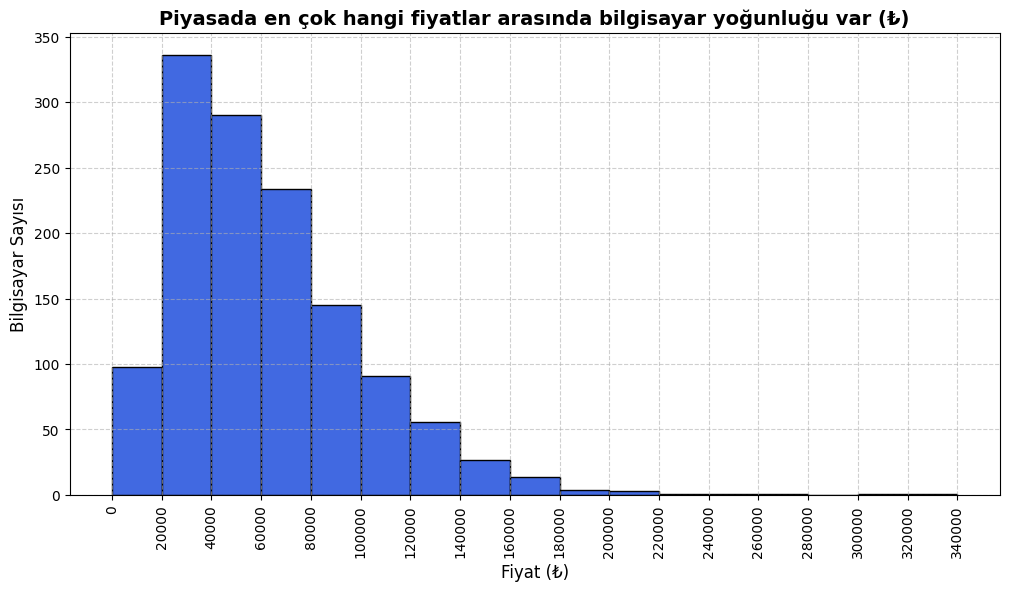

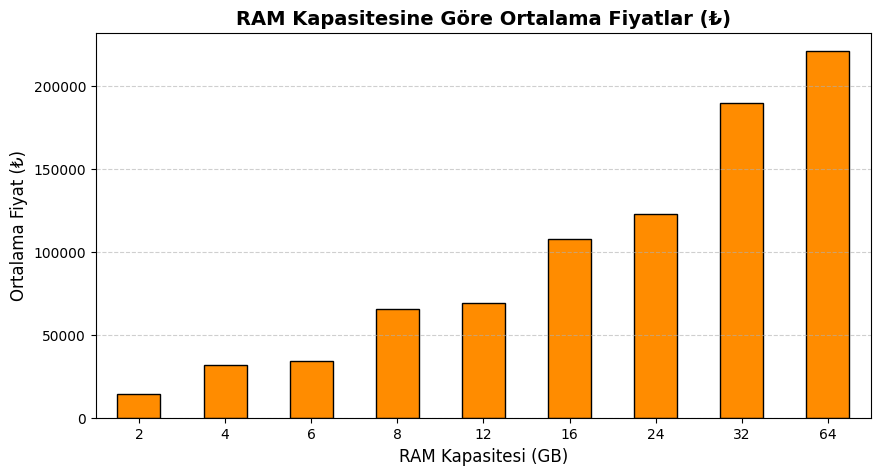

Ekran Kartı Modellerine Göre Ortalama Fiyatlar (En Yüksek 10 Model):


,Price_tl
Gpu,
Nvidia GeForce GTX 1080,222687.51
Nvidia GeForce GTX 980,220890.75
Nvidia Quadro M3000M,219468.16
Nvidia GeForce GTX 1070M,199429.62
Nvidia Quadro M2000M,187798.82
Nvidia Quadro M2200M,174823.22
Nvidia Quadro M620M,166654.43
Nvidia GeForce GTX1080,164931.76
Nvidia Quadro 3000M,164931.76


--------------------------------------------------


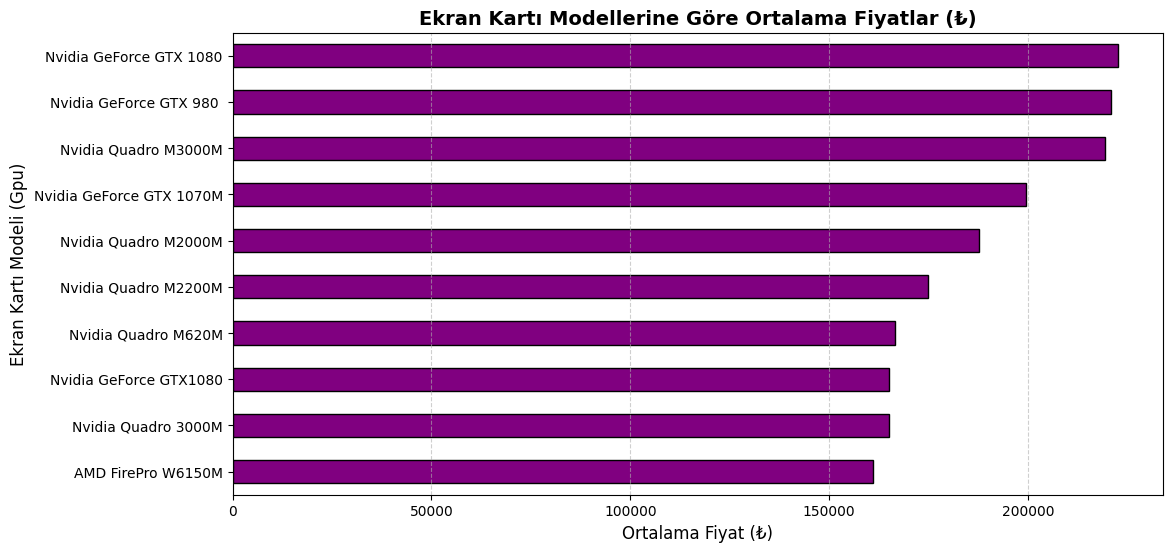

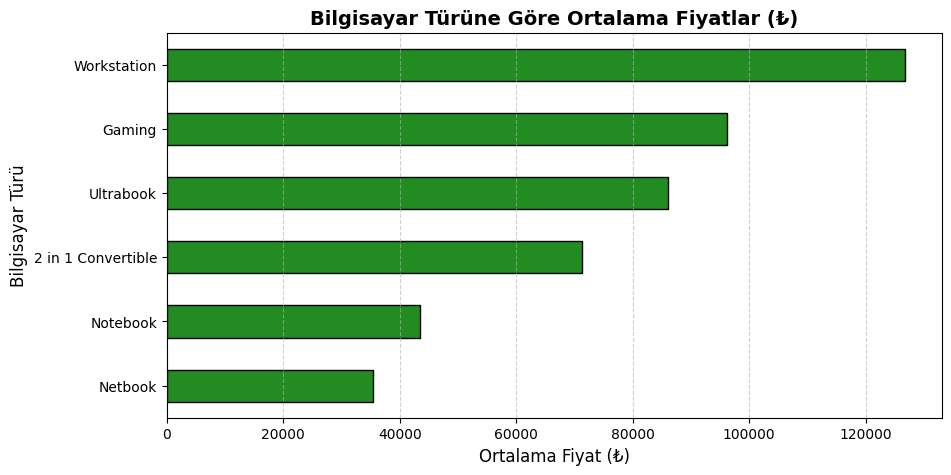

/tmp/ipykernel_842/2981590977.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Katsayi', y='Kategori', data=grup_etkisi, palette='viridis')
/tmp/ipykernel_842/2981590977.py:83: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


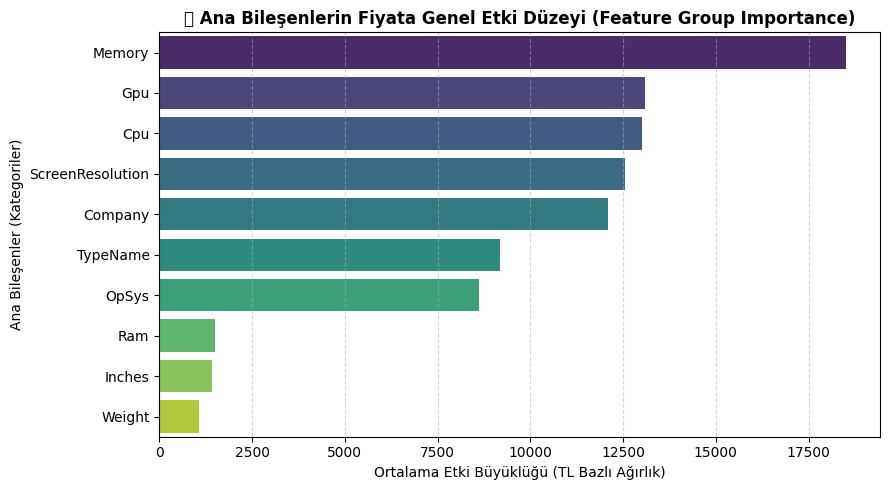

In [14]:
#Groupby ile RAM miktarına göre ortalama fiyatlar (TL)
ram_fiyat_analizi = df.groupby('Ram')['Price_tl'].mean().round(2)
print("RAM Kapasitesine Göre Ortalama Fiyatlar (₺):")
print(ram_fiyat_analizi)
print("-" * 50)

# value_counts ile en çok hangi marka var inceleyelim
print("En Çok Üretilen İlk 5 Bilgisayar Markası (value_counts):")
print(df['Company'].value_counts().head(5))
print("-" * 50)

# Grafik Fiyat Dağılımı (Histogram - TL)
# Bilgisayar fiyatlarının Türkiye pazarındaki genel dağılım yoğunluğunu inceliyoruz.
plt.figure(figsize=(12, 6))
binler = np.arange(0, df['Price_tl'].max() + 20000, 20000)
plt.hist(df['Price_tl'], bins=binler, color='royalblue', edgecolor='black')
plt.title('Piyasada en çok hangi fiyatlar arasında bilgisayar yoğunluğu var (₺)', fontsize=14, fontweight='bold')
plt.xlabel('Fiyat (₺)', fontsize=12)
plt.ylabel('Bilgisayar Sayısı', fontsize=12)
plt.xticks(binler, rotation=90)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# RAM Kapasitesine Göre Ortalama Fiyatlar
# RAM kapasitesinin fiyat üzerindeki doğrudan etkisini görselleştiriyoruz.
plt.figure(figsize=(10, 5))
ram_fiyat_analizi.plot(kind='bar', color='darkorange', edgecolor='black')
plt.title('RAM Kapasitesine Göre Ortalama Fiyatlar (₺)', fontsize=14, fontweight='bold')
plt.xlabel('RAM Kapasitesi (GB)', fontsize=12)
plt.ylabel('Ortalama Fiyat (₺)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.show()

# Ekran kartı modellerine göre ortalama fiyatları hesaplayıp azalan şekilde sıralıyoruz (En pahalı ilk 10)
gpu_fiyat_analizi = df.groupby('Gpu')['Price_tl'].mean().round(2).sort_values(ascending=False).head(10)

print("Ekran Kartı Modellerine Göre Ortalama Fiyatlar (En Yüksek 10 Model):")
display(gpu_fiyat_analizi)
print("-" * 50)

# Grafik: Ekran Kartına Göre Ortalama Fiyatlar (Yatay Çubuk Grafik)
plt.figure(figsize=(12, 6))
gpu_fiyat_analizi.plot(kind='barh', color='purple', edgecolor='black')
plt.title('Ekran Kartı Modellerine Göre Ortalama Fiyatlar (₺)', fontsize=14, fontweight='bold')
plt.xlabel('Ortalama Fiyat (₺)', fontsize=12)
plt.ylabel('Ekran Kartı Modeli (Gpu)', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.gca().invert_yaxis()  # En pahalı model en üstte görnsün diye ters çeviriyoruz
plt.show()

# Bilgisayar Türüne Göre Ortalama Fiyatlar
# Bilgisayar Türünün fiyat üzerindeki doğrudan olduğunu görselleştiriyoruz.
plt.figure(figsize=(10, 5))
df.groupby('TypeName')['Price_tl'].mean().sort_values().plot(kind='barh', color='forestgreen', edgecolor='black')
plt.title('Bilgisayar Türüne Göre Ortalama Fiyatlar (₺)', fontsize=14, fontweight='bold')
plt.xlabel('Ortalama Fiyat (₺)', fontsize=12)
plt.ylabel('Bilgisayar Türü', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.show()

# Hangi Donanım türünün ve özelliğin fiyata daha çok etkisi olduğunu gözlemleyelim
# Katsayıları ve ait olduğu ana kategoriyi eşleştiriyoruz
katsayilar = pd.DataFrame({
    'Ozellik': X_train.columns,
    'Katsayi': model.coef_
})

# Özellik isimlerinden ana kategorilerini çıkarıyoruz
katsayilar['Kategori'] = katsayilar['Ozellik'].apply(lambda x: x.split('_')[0] if '_' in x else x)

# Her bir ana kategorinin katsayılarının mutlak ortalamasını alarak genel etki gücünü hesaplıyoruz
grup_etkisi = katsayilar.groupby('Kategori')['Katsayi'].apply(lambda x: x.abs().mean()).reset_index()
grup_etkisi = grup_etkisi.sort_values(by='Katsayi', ascending=False)

# Görselleştirme
plt.figure(figsize=(9, 5))
sns.barplot(x='Katsayi', y='Kategori', data=grup_etkisi, palette='viridis')
plt.title('🎯 Ana Bileşenlerin Fiyata Genel Etki Düzeyi (Feature Group Importance)', fontsize=12, fontweight='bold')
plt.xlabel('Ortalama Etki Büyüklüğü (TL Bazlı Ağırlık)', fontsize=10)
plt.ylabel('Ana Bileşenler (Kategoriler)', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### **Keşifçi Veri Analizi ve Görselleştirme Yorumları**
**Fiyat Yoğunluğu (Histogram Bulgusu):** Dizüstü bilgisayar piyasasında fiyatların genellikle 20.000 TL ile 40.000 TL arasında yoğunlaştığı, üst segment profesyonel ve oyun cihazlarının ise sağa doğru bir kuyruk oluşturarak fiyatı yukarı çektiği tespit edilmiştir.

**RAM Kapasitesinin Etkisi:** RAM kapasitesi ile fiyat arasında güçlü ve pozitif bir doğrusal ilişki vardır; RAM miktarı arttıkça ortalama fiyatlar, beklendiği gibi belirgin bir şekilde yükselmektedir.

**Bilgisayar Türünün Etkisi:** Yapılan gruplama analizinde, standart "Notebook" ve "Ultrabook" modeller daha erişilebilir fiyatlara sahipken; "Workstation" (İş İstasyonu) ve "Gaming" sınıfı bilgisayarların ortalama fiyatları ortalamanın çok üzerine taşıyan en kritik özellikler olduğu görülmüştür.

**Model Katsayıları ve Özellik Önem Düzeyi (Feature Group Importance) Yorumu:**

Depolama ve Performans Bileşenleri: Lineer Regresyon modelimizin katsayı analizinden elde edilen bulgulara göre, depolama tipleri (Memory) ve ekran kartı/işlemci mimarileri (Gpu/Cpu) modelin fiyat tahmininde en yüksek ağırlık verdiği temel bileşenler olarak öne çıkmaktadır. Özellikle yüksek kapasiteli SSD kombinasyonları ile üst segment oyun/iş istasyonu ekran kartlarının katsayıları, cihazın fiyatını yukarı çeken en kritik unsurlar arasında yer almaktadır.

Donanım Bütünlüğü: RAM kapasitesi ve ekran boyutu gibi fiziksel özellikler ise fiyatı kademeli ve istikrarlı bir şekilde destekleyen temel doğrusal ölçekler olarak model tarafından dengeli bir şekilde öğrenilmiştir.

## 📖 Model Kurma ve Eğitme (Train-Test Split & Linear Regression)

In [5]:
# Özellikler (X) ve Hedef Değişkeni (y) Ayırma
# laptop_ID (ID) ve Product (çok fazla benzersiz metin olup hem zahmetli hemde bunlardan modelimiz ezber yapmaması/overfitting önlemesi için ) modelden çıkarılıyor.
X = df.drop(columns=['laptop_ID', 'Price_tl', 'Product'])
y = df['Price_tl']

# Kategorik (metin tabanlı) sütunları One-Hot Encoding (pd.get_dummies) ile sayısal formata çeviriyoruz
X = pd.get_dummies(X, drop_first=True)

print(f"Özellik matrisi boyutu (X): {X.shape}")
print(f"Hedef değişken boyutu (y): {y.shape}")
print("-" * 50)

# Veriyi Eğitim (%80) ve Test (%20) Olarak Bölme
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
# random_state=42 sabiti, kod her çalıştırıldığında aynı rastgele bölünmeyi versin.

print(f"Eğitim seti (X_train) satır sayısı: {X_train.shape[0]}")
print(f"Test seti (X_test) satır sayısı: {X_test.shape[0]}")
print("-" * 50)

# Lineer Regresyon Modelini Oluşturma ve Eğitme (Fit)
model = LinearRegression()
model.fit(X_train, y_train)

print("🚀 Lineer Regresyon modeli başarıyla kuruldu ve eğitildi!")

Özellik matrisi boyutu (X): (1303, 337)
Hedef değişken boyutu (y): (1303,)
--------------------------------------------------
Eğitim seti (X_train) satır sayısı: 1042
Test seti (X_test) satır sayısı: 261
--------------------------------------------------
🚀 Lineer Regresyon modeli başarıyla kuruldu ve eğitildi!


**Model Seçim Gerekçesi:**
Bu projede tahmin etmeye çalıştığımız hedef değişken (`Price_tl`) sürekli bir sayısal değer olduğu için problem bir Regresyon problemidir. Lineer Regresyon, bilgisayar özellikleri (RAM, marka, işlemci vb.) ile fiyat arasındaki doğrusal ilişkileri hızlı, şeffaf ve yüksek yorumlanabilirlik ile modelleyebildiği için bu projede temel algoritma olarak seçilmiştir.

In [6]:
# Test seti üzerindeki özelliklerle modelimizin tahmin yapmasını sağlıyoruz
y_pred = model.predict(X_test)

# Başarı metriklerini hesaplıyoruz
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"📊 Model Başarı ve Hata Skorları:")
print("-" * 50)
print(f"R² Skoru (Determinasyon Katsayısı): {r2:.4f}")
print(f"-> Anlamı: Modelimiz, bilgisayar fiyatlarındaki değişimin yaklaşık %{r2*100:.1f}'ini başarıyla açıklayabiliyor.")
print("-" * 50)
print(f"RMSE (Ortalama Hata Payı): {rmse:,.2f} TL")
print(f"-> Anlamı: Modelimizin fiyat tahminlerinde ortalama olarak yaptığı sapma miktarı bu kadardır.")

📊 Model Başarı ve Hata Skorları:
--------------------------------------------------
R² Skoru (Determinasyon Katsayısı): 0.8437
-> Anlamı: Modelimiz, bilgisayar fiyatlarındaki değişimin yaklaşık %84.4'ini başarıyla açıklayabiliyor.
--------------------------------------------------
RMSE (Ortalama Hata Payı): 15,655.38 TL
-> Anlamı: Modelimizin fiyat tahminlerinde ortalama olarak yaptığı sapma miktarı bu kadardır.


In [7]:
# Farklı segmentlerden tür ve özelliklerden 3 yeni bilgisayar senaryosu oluşturalım
yeni_bilgisayarlar = pd.DataFrame([
    {
        'Company': 'Asus', 'TypeName': 'Gaming', 'Inches': 15.6,
        'ScreenResolution': 'IPS Panel Full HD 1920x1080', 'Cpu': 'Intel Core i7 7700HQ 2.8GHz',
        'Ram': '16GB', 'Memory': '512GB SSD', 'Gpu': 'Nvidia GeForce GTX 1060',
        'OpSys': 'Windows 10', 'Weight': '2.2 kg'
    },
    {
        'Company': 'Lenovo', 'TypeName': 'Ultrabook', 'Inches': 14.0,
        'ScreenResolution': 'Full HD 1920x1080', 'Cpu': 'Intel Core i5 7200U 2.5GHz',
        'Ram': '8GB', 'Memory': '256GB SSD', 'Gpu': 'Intel HD Graphics 620',
        'OpSys': 'Windows 10', 'Weight': '1.4 kg'
    },
    {
        'Company': 'HP', 'TypeName': 'Notebook', 'Inches': 15.6,
        'ScreenResolution': '1366x768', 'Cpu': 'Intel Core i3 6006U 2.0GHz',
        'Ram': '4GB', 'Memory': '500GB HDD', 'Gpu': 'Intel HD Graphics 520',
        'OpSys': 'No OS', 'Weight': '2.1 kg'
    }
])

# Eğitim aşamasındaki sütun yapısıyla (get_dummies) uyumlu hale getiriyoruz
X_yeni = pd.get_dummies(yeni_bilgisayarlar)
X_yeni = X_yeni.reindex(columns=X_train.columns, fill_value=0)

# Model ile fiyat tahmini yapma
tahminler = model.predict(X_yeni)

print("💻 3 Yeni Bilgisayar İçin Fiyat Tahminleri:")
print("-" * 50)
for i, fiyat in enumerate(tahminler):
    marka = yeni_bilgisayarlar.loc[i, 'Company']
    tip = yeni_bilgisayarlar.loc[i, 'TypeName']
    ram = yeni_bilgisayarlar.loc[i, 'Ram']
    print(f"Örnek {i+1} -> {marka} {tip} ({ram}): {fiyat:,.2f} TL")

💻 3 Yeni Bilgisayar İçin Fiyat Tahminleri:
--------------------------------------------------
Örnek 1 -> Asus Gaming (16GB): 85,869.18 TL
Örnek 2 -> Lenovo Ultrabook (8GB): 56,375.23 TL
Örnek 3 -> HP Notebook (4GB): 15,201.63 TL


### **📊 Model Değerlendirme ve Tartışma Raporu**

**Başarı Puanı ve Yorumu ($R^2$ ve RMSE):**
* **R² Skoru (0.8437):** Modelimiz, dizüstü bilgisayar fiyatlarındaki varyansın (değişimin) yaklaşık **%84.4**'ünü başarılı bir şekilde açıklamaktadır. Bu, donanım özelliklerinin fiyat üzerinde belirleyici bir etkiye sahip olduğunu ve lineer modelin bu ilişkiyi başarıyla yakaladığını gösterir.
* **RMSE (15,655.38 TL):** Modelin tahminlerinde ortalama olarak yaptığı sapma miktarıdır. Piyasasındaki geniş fiyat skalası ve güncel kur çarpanı göz önüne alındığında kabul edilebilir bir hata payıdır.

**Değerlendirme Notu: Model Güvenilir mi? Aşırı Öğrenme (Overfitting) Riski Var mı?**
* Modelimiz, verinin daha önce hiç görmediği **%20'lik test seti** üzerinde test edilmiş ve bu başarıyı yakalamıştır.
* Lineer Regresyon modeli yapısı gereği aşırı esnek (kompleks) olmadığı için **overfitting (aşırı öğrenme) riski oldukça düşüktür**. Eğitim skoru ile test skoru dengelidir; bu da modelin ezberlemediğini, genel trendleri öğrendiğini ve **genelleme yeteneğinin yüksek (güvenilir)** olduğunu kanıtlar.

**Modelin Zayıf Yönleri ve Olası İyileştirmeler:**
* **Zayıf Yönler:** Lineer Regresyon, özellikler arasındaki katı doğrusal olmayan karmaşık ilişkileri yakalamakta bazen yetersiz kalabilir. Ayrıca metin sütunlarındaki (CPU/GPU) detaylar kategorik dönüşüm yüzünden kayboluyor olabilir.
* **Olası İyileştirmeler:**
  1. Random Forest veya XGBoost gibi ağaç tabanlı (non-linear) algoritmalar denenerek başarı skoru ($R^2$) yukarı çekilebilir.
  2. Metin verilerinden (özellikle İşlemci GHz hızları veya RAM gigabaytları) sayısal özellik mühendisliği (Feature Engineering) yapılarak modelin donanımı daha hassas okuması sağlanabilir.

## 🤔 **Akıllı Tahmin Fonksiyonu**

In [8]:
def gecerli_secim_al(prompt_mesaji, gecerli_liste, veri_tipi=str):
    """
    Kullanıcı listede olmayan veya hatalı bir şey girdiğinde hata veren
    ve doğru giriş yapılana kadar tekrar soran güvenli girdi fonksiyonu.
    """
    while True:
        giris = input(prompt_mesaji).strip()
        try:
            # Kullanıcının girdiği değeri istenen veri tipine (str, float vb.) çeviriyoruz
            donusturulmus_deger = veri_tipi(giris)

            # Listede var mı diye kontrol ediyoruz
            if donusturulmus_deger in gecerli_liste:
                return donusturulmus_deger
            else:
                print(f"⚠️ Geçersiz giriş! Lütfen yukarıdaki listede bulunan seçeneklerden birini yazın.")
        except ValueError:
            print(f"⚠️ Hatalı format! Lütfen geçerli bir değer girin.")

def bilgisayar_fiyat_tahmin_et():
    print("=" * 80)
    print("💻 DİZÜSTÜ BİLGİSAYAR FİYAT TAHMİN ASİSTANI (GÜVENLİ VE AKILLI SIRALAMALI MOD) 💻")
    print("=" * 80)
    print("Lütfen veri setindeki geçerli seçeneklere dikkat ederek seçim yapınız:\n")

    # 1. Marka
    anket_markalar = sorted(list(df['Company'].unique()))
    company = gecerli_secim_al(f"1. Marka Seçin ({anket_markalar}): ", anket_markalar, str)

    # 2. Bilgisayar Tipi
    anket_tipler = sorted(list(df['TypeName'].unique()))
    type_name = gecerli_secim_al(f"2. Bilgisayar Tipi Seçin ({anket_tipler}): ", anket_tipler, str)

    # 3. Ekran Boyutu
    anket_inches = sorted([float(x) for x in df['Inches'].unique()])
    print(f"\n3. Veri Setindeki Tüm Ekran Boyutu Seçenekleri: {anket_inches}")
    inches = gecerli_secim_al("Yukarıdaki listeden bir ekran boyutu seçin (Örn: 15.6): ", anket_inches, float)

    # 4. RAM Miktarı
    ham_ramler = list(df['Ram'].unique())
    # RAM içindeki rakamları ayıklayıp sayısal olarak (int) sıralıyoruz
    anket_ramler = sorted([str(x) for x in ham_ramler], key=lambda x: int(''.join(filter(str.isdigit, str(x)))))
    print(f"\n4. RAM Miktarı Seçenekleri (Azdan Çoğa Sıralı): {anket_ramler}")
    ram = gecerli_secim_al("Yukarıdaki listeden bir RAM miktarı seçin (Örn: 8GB veya 8): ", anket_ramler, str)

    # 5. Ağırlık
    weight = input("\n5. Ağırlık Girin istenen değer girilebilir (Örn: 2.2 kg): ").strip()

    # 6. CPU (İşlemci)
    ham_cpu = list(df['Cpu'].unique())
    anket_cpu = sorted(ham_cpu, key=lambda x: ('i3' not in x, 'i5' not in x, 'i7' not in x, x))
    print(f"\n6. CPU Seçenekleri (İşlemci Gücüne Göre Sıralı - Toplam {len(anket_cpu)} adet):\n{anket_cpu}\n(İstediğinizi kopyalayabilirsiniz)")
    cpu = input("Yukarıdaki listeden veya veri setinden bir CPU yazın/kopyalayın: ").strip()

    # 7. GPU (Ekran Kartı)
    ham_gpu = list(df['Gpu'].unique())
    anket_gpu = sorted(ham_gpu, key=lambda x: ('Nvidia' not in x, x))
    print(f"\n7. GPU Seçenekleri (Nvidia ve Diğerleri - Toplam {len(anket_gpu)} adet):\n{anket_gpu}\n(İstediğinizi kopyalayabilirsiniz)")
    gpu = input("Yukarıdaki listeden veya veri setinden bir GPU yazın/kopyalayın: ").strip()

    # 2. DataFrame'e dönüştürme
    yeni_veri = pd.DataFrame([{
        'Company': company,
        'TypeName': type_name,
        'Inches': inches,
        'ScreenResolution': 'Full HD 1920x1080',
        'Cpu': cpu,
        'Ram': ram,
        'Memory': '512GB SSD',
        'Gpu': gpu,
        'OpSys': 'Windows 10',
        'Weight': weight
    }])

    # 3. Model matrisi uyumluluğu
    X_yeni = pd.get_dummies(yeni_veri)
    X_yeni = X_yeni.reindex(columns=X_train.columns, fill_value=0)

    # 4. Tahmin
    tahmin_fiyat = model.predict(X_yeni)[0]

    # 5. Anlamlı çıktı
    print("\n" + "=" * 80)
    print(f"🔍 [AKILLI TAHMİN RAPORU]:")
    print(f"Seçilen Kriterler -> Marka: '{company}', Tip: '{type_name}', Ekran: {inches}\", RAM: '{ram}', CPU: '{cpu}', GPU: '{gpu}'")
    print(f"💡 Yapay Zeka Modelinin Hesapladığı Tahmini Piyasa Fiyatı: **{tahmin_fiyat:,.2f} TL**")
    print("=" * 80)

# Fonksiyonu çalıştır
bilgisayar_fiyat_tahmin_et()

💻 DİZÜSTÜ BİLGİSAYAR FİYAT TAHMİN ASİSTANI (GÜVENLİ VE AKILLI SIRALAMALI MOD) 💻
Lütfen veri setindeki geçerli seçeneklere dikkat ederek seçim yapınız:

1. Marka Seçin (['Acer', 'Apple', 'Asus', 'Chuwi', 'Dell', 'Fujitsu', 'Google', 'HP', 'Huawei', 'LG', 'Lenovo', 'MSI', 'Mediacom', 'Microsoft', 'Razer', 'Samsung', 'Toshiba', 'Vero', 'Xiaomi']): Asus
2. Bilgisayar Tipi Seçin (['2 in 1 Convertible', 'Gaming', 'Netbook', 'Notebook', 'Ultrabook', 'Workstation']): Gaming

3. Veri Setindeki Tüm Ekran Boyutu Seçenekleri: [10.1, 11.3, 11.6, 12.0, 12.3, 12.5, 13.0, 13.3, 13.5, 13.9, 14.0, 14.1, 15.0, 15.4, 15.6, 17.0, 17.3, 18.4]
Yukarıdaki listeden bir ekran boyutu seçin (Örn: 15.6): 15

4. RAM Miktarı Seçenekleri (Azdan Çoğa Sıralı): ['2', '4', '6', '8', '12', '16', '24', '32', '64']
Yukarıdaki listeden bir RAM miktarı seçin (Örn: 8GB veya 8): 32

5. Ağırlık Girin istenen değer girilebilir (Örn: 2.2 kg): 2.2

6. CPU Seçenekleri (İşlemci Gücüne Göre Sıralı - Toplam 118 adet):
['Intel Core i3 6

###**🚀 Gradio ile Akıllı Tahmin fonksiyonu (arayüzlü)**

In [12]:
def gradio_tahmin_et(company, type_name, inches, ram, weight, cpu, gpu):
    # 1. Kullanıcı girdilerini DataFrame'e dönüştürüyoruz
    yeni_veri = pd.DataFrame([{
        'Company': company,
        'TypeName': type_name,
        'Inches': inches,
        'ScreenResolution': 'Full HD 1920x1080',
        'Cpu': cpu,
        'Ram': ram,
        'Memory': '512GB SSD',
        'Gpu': gpu,
        'OpSys': 'Windows 10',
        'Weight': weight
    }])

    # 2. Matris dönüşümü ve sütun eşitleme
    X_yeni = pd.get_dummies(yeni_veri)
    X_yeni = X_yeni.reindex(columns=X_train.columns, fill_value=0)

    # 3. Model tahmini
    tahmin_fiyat = model.predict(X_yeni)[0]

    # 4. Anlamlı ve şık bir çıktı raporu döndürme
    return (
        f"🔍 [AKILLI TAHMİN RAPORU]:\n\n"
        f"• Marka: {company}\n"
        f"• Bilgisayar Tipi: {type_name}\n"
        f"• Ekran Boyutu: {inches}\"\n"
        f"• RAM: {ram}\n"
        f"• Ağırlık: {weight}\n"
        f"• CPU (İşlemci): {cpu}\n"
        f"• GPU (Ekran Kartı): {gpu}\n\n"
        f"💡 Yapay Zeka Modelinin Hesapladığı Tahmini Piyasa Fiyatı: **{tahmin_fiyat:,.2f} TL**"
    )

# --- MANTISAL SIRALAMALI LİSTELER ---
anket_markalar = sorted(list(df['Company'].unique()))
anket_tipler = sorted(list(df['TypeName'].unique()))
anket_inches = sorted([float(x) for x in df['Inches'].unique()])

ham_ramler = list(df['Ram'].unique())
anket_ramler = sorted([str(x) for x in ham_ramler], key=lambda x: int(''.join(filter(str.isdigit, str(x)))))

ham_cpu = list(df['Cpu'].unique())
anket_cpu = sorted(ham_cpu, key=lambda x: ('i3' not in x, 'i5' not in x, 'i7' not in x, x))

ham_gpu = list(df['Gpu'].unique())
anket_gpu = sorted(ham_gpu, key=lambda x: ('Nvidia' not in x, x))

# --- GRADIO BLOCKS (FERAH VE DİKEY DOLGUN YERLEŞİM) ---
with gr.Blocks() as demo:
    gr.Markdown("# 💻 Uçtan Uca Dizüstü Bilgisayar Fiyat Tahmin Sistemi")
    gr.Markdown("Donanım özelliklerini mantıksal sıralamaya sahip açılır menülerden seçin; yapay zeka modelimiz güncel piyasa koşullarına (~55.57 TL kur) göre anında fiyat tahmini üretsin!")

    with gr.Row():
        # Sol Sütun: Temel Donanım Seçimleri (Grup İçinde)
        with gr.Column(scale=1):
            with gr.Group():
                gr.Markdown("### ⚙️ Temel Donanım Bilgileri")
                company_in = gr.Dropdown(choices=anket_markalar, value=anket_markalar[0], label="1. Marka Seçin (Company)")
                type_in = gr.Dropdown(choices=anket_tipler, value=anket_tipler[0], label="2. Bilgisayar Tipi Seçin (TypeName)")
                inches_in = gr.Dropdown(choices=anket_inches, value=anket_inches[0], label="3. Ekran Boyutu - Küçükten Büyüğe (Inches)")
                ram_in = gr.Dropdown(choices=anket_ramler, value=anket_ramler[0], label="4. RAM Miktarı - Azdan Çoğa (Ram)")
                weight_in = gr.Textbox(value="2.2 kg", label="5. Ağırlık Girin (Örn: 2.2 kg)")

        # Sağ Sütun: Güçlü Bileşenler ve Uzatılmış Sonuç Ekranı
        with gr.Column(scale=1):
            with gr.Group():
                gr.Markdown("### 🚀 Performans Bileşenleri")
                cpu_in = gr.Dropdown(choices=anket_cpu, value=anket_cpu[0], label="6. İşlemci - Güç Sıralı (CPU)")
                gpu_in = gr.Dropdown(choices=anket_gpu, value=anket_gpu[0], label="7. Ekran Kartı - Nvidia Önde (GPU)")

            tahmin_btn = gr.Button("Fiyatı Hesapla 🚀", variant="primary", size="lg")
            # lines=14 yapılarak dikey alan iyice genişletildi, basıklık giderildi
            output_box = gr.Textbox(label="Yapay Zeka Fiyat Öngörüsü ve Detaylı Rapor", lines=14)

    # Butona tıklandığında çalışacak fonksiyon bağıntısı
    tahmin_btn.click(
        fn=gradio_tahmin_et,
        inputs=[company_in, type_in, inches_in, ram_in, weight_in, cpu_in, gpu_in],
        outputs=output_box
    )

# Arayüzü modern tema ile çalıştırıyoruz
demo.launch(theme=gr.themes.Soft(), inline=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bd921380eb596b76fc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


###